# 02 · Catchment climate

1. Catchment-average monthly series of P, T, Tmax and Tmin (area-weighted mean of the ERA5-Land cells
   inside `catchment.kml`, with `meteoraster`).
2. Units: temperature K → °C ($T_{°C} = T_K - 273.15$); precipitation from mean daily rate (m/day)
   to monthly total: $P_{mm/month} = tp \cdot 1000 \cdot n_{days}$.
3. Annual totals by hydrological year (October–September), monthly climatology, driest and wettest years.

In [1]:
%load_ext autoreload
%autoreload 2                  # reload edited src/epss modules automatically
import sys, json
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
PROC = DATA / "processed"
PROC.mkdir(exist_ok=True)
case = json.loads((DATA / "case.json").read_text())
case

{'catchment_area_km2': 55.33,
 'latitude_deg': 38.237,
 'longitude_deg': -7.687,
 'smax_mm': 100,
 'hmax_m': 5.0,
 'hmin_m': 1.0,
 'area_fixed_km2': 0.0685,
 'irrigation_months': [6, 7, 8, 9],
 'demand_hm3_per_month': 0.02,
 'eflow_fraction': 0.1,
 'target_reliability': 0.9}

In [2]:
from epss.climate import catchment_series, kelvin_to_celsius, to_monthly_mm

kml = DATA / "catchment.kml"
era5, txn = DATA / "raw" / "era5land_monthly.nc", DATA / "raw" / "tmax_tmin.nc"
clim = pd.DataFrame({
    "p_mm": to_monthly_mm(catchment_series(era5, kml, "tp")),
    "t_c": kelvin_to_celsius(catchment_series(era5, kml, "t2m")),
    "tmax_c": kelvin_to_celsius(catchment_series(txn, kml, "tmax")),
    "tmin_c": kelvin_to_celsius(catchment_series(txn, kml, "tmin")),
})
clim.to_csv(PROC / "climate.csv")
clim.describe().round(1)

,p_mm,t_c,tmax_c,tmin_c
count,480.0,480.0,480.0,480.0
mean,43.2,17.0,22.6,12.1
std,45.1,5.9,6.9,4.7
min,0.0,7.6,11.9,2.4
25%,7.9,11.8,16.3,8.2
50%,31.7,16.1,21.3,11.5
75%,61.0,22.7,29.1,16.5
max,278.8,28.8,36.7,21.2


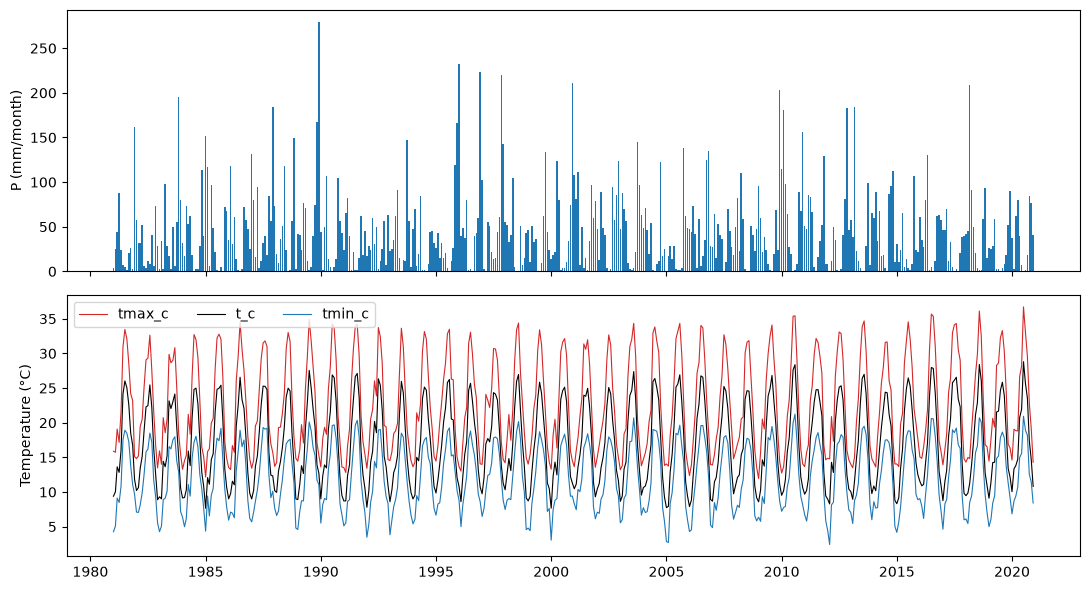

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].bar(clim.index, clim.p_mm, width=25)
ax[0].set_ylabel("P (mm/month)")
for col, color in [("tmax_c", "tab:red"), ("t_c", "k"), ("tmin_c", "tab:blue")]:
    ax[1].plot(clim.index, clim[col], color=color, lw=0.8, label=col)
ax[1].legend(ncol=3)
ax[1].set_ylabel("Temperature (°C)")
plt.tight_layout()

## Hydrological years and climatology
Use only complete hydrological years (October 1981 – September 2020). `resample("YS-OCT")` labels each
year by the October in which it starts.

In [4]:
# TODO: Annual P by hydrological year (Oct-Sep, complete years Oct 1981-Sep 2020;
#       resample('YS-OCT').sum(), index = start year) and the monthly climatology (mean by
#       calendar month).
# In: clim (DataFrame p_mm, t_c, tmax_c, tmin_c)
# Out: annual_p (pd.Series, mm/year), monthly (DataFrame, months 1-12)
raise NotImplementedError("Annual P by hydrological year (Oct-Sep, complete years Oct 1981-Sep 2020; resample('YS-OCT').sum(), index = start year) and the monthly climatology (mean by calendar month).")
print(f"Mean annual P: {annual_p.mean():.0f} mm, CV = {annual_p.std() / annual_p.mean():.2f}")
print("Driest years:", annual_p.nsmallest(3).round(0).to_dict())
print("Wettest years:", annual_p.nlargest(3).round(0).to_dict())

Mean annual P: 520 mm, CV = 0.28
Driest years: {2004: 262.0, 1994: 288.0, 1998: 316.0}
Wettest years: {2009: 810.0, 1995: 793.0, 1997: 765.0}


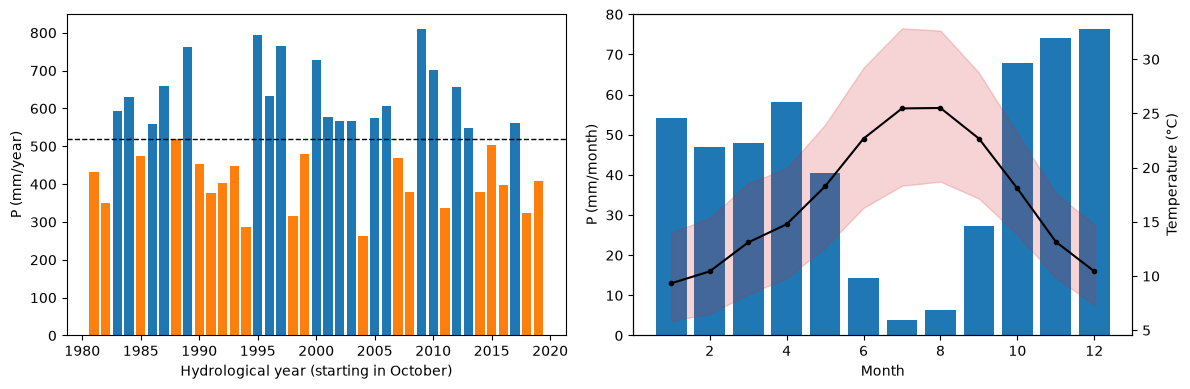

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(annual_p.index, annual_p, color=np.where(annual_p < annual_p.mean(), "tab:orange", "tab:blue"))
ax[0].axhline(annual_p.mean(), color="k", ls="--", lw=1)
ax[0].set_xlabel("Hydrological year (starting in October)"); ax[0].set_ylabel("P (mm/year)")
ax[1].bar(monthly.index, monthly.p_mm, color="tab:blue")
ax[1].set_xlabel("Month"); ax[1].set_ylabel("P (mm/month)")
ax2 = ax[1].twinx()
ax2.plot(monthly.index, monthly.t_c, "k-o", ms=3)
ax2.fill_between(monthly.index, monthly.tmin_c, monthly.tmax_c, color="tab:red", alpha=0.2)
ax2.set_ylabel("Temperature (°C)")
plt.tight_layout()

**Answer.**

*Your answer here.*